# Graficando `DataFrames`

Vamos a ver brevemente cómo usar `matplotlib` para graficar `DataFrames` de `pandas`. La mecánica para utilizar otras bibliotecas de graficación (`seaborn`, `plotly`, etc.) es similar

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [4]:
s = pd.Series(np.random.standard_normal(1000).cumsum(), index=pd.date_range('2019-1-1', periods=1000))
s

2019-01-01    -1.054752
2019-01-02    -1.481344
2019-01-03     0.011864
2019-01-04     0.572930
2019-01-05    -1.124467
                ...    
2021-09-22   -16.872039
2021-09-23   -17.249404
2021-09-24   -16.116352
2021-09-25   -15.841262
2021-09-26   -16.401571
Freq: D, Length: 1000, dtype: float64

<Axes: >

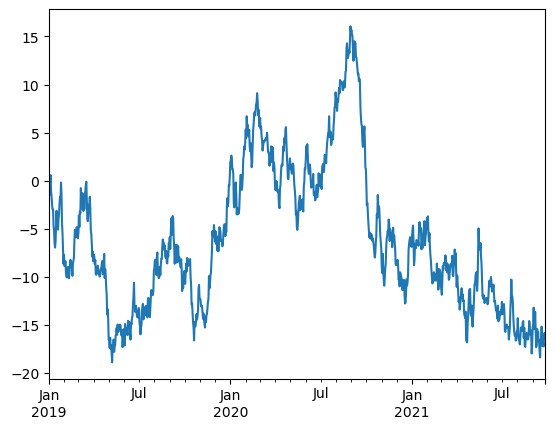

In [5]:
s.plot()

<Axes: title={'center': 'Random Series'}>

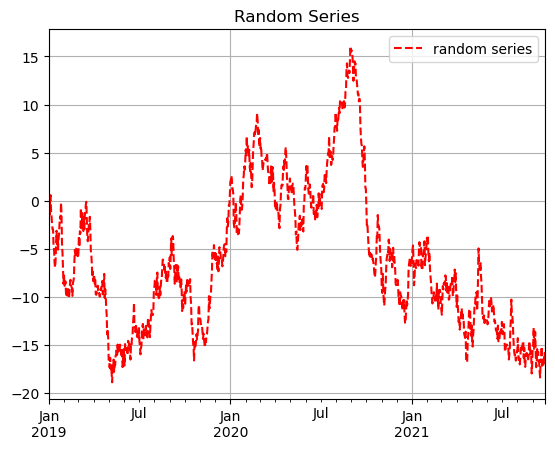

In [6]:
s.plot(label='random series',style='r--',legend=True, title='Random Series', grid=True)

In [8]:
df = pd.DataFrame({'A': np.random.standard_normal(100)+2, 'B': np.random.standard_normal(100), 'C': np.random.standard_normal(100)-2, 'D': np.random.randn(100) }, index=pd.date_range('2019-1-1', periods=100))
df.head(5)

,A,B,C,D
2019-01-01,1.829692,0.282345,-2.012119,-0.342792
2019-01-02,3.225317,-0.409511,-0.850950,0.565629
2019-01-03,3.054147,0.062357,-1.368139,0.653424
2019-01-04,1.955376,0.225909,-1.269216,-0.987626
2019-01-05,0.920553,0.123801,-2.118329,0.342195


<Axes: >

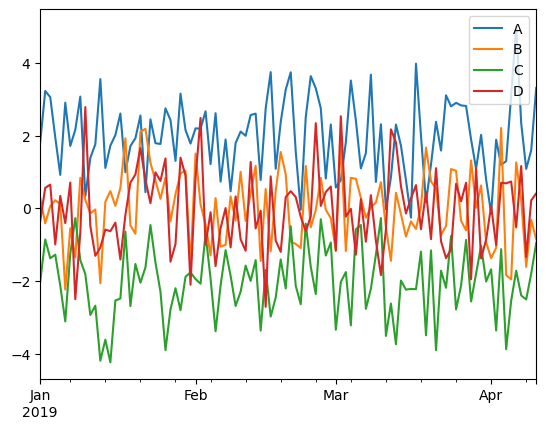

In [9]:
df.plot()

<Axes: title={'center': 'Random DataFrame'}>

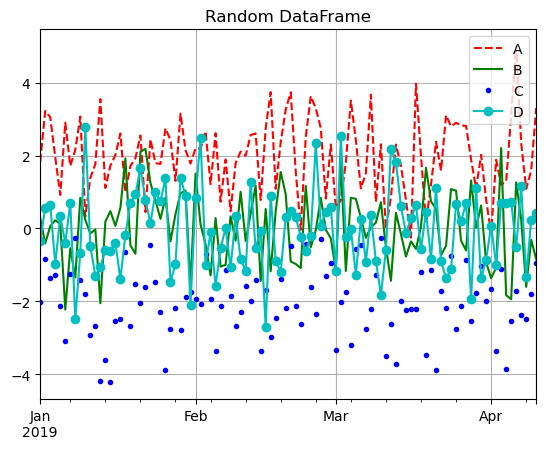

In [10]:
df.plot(legend=True, title='Random DataFrame', grid=True, style=['r--','g-','b.','co-'], kind='line')

<Axes: title={'center': 'D'}>

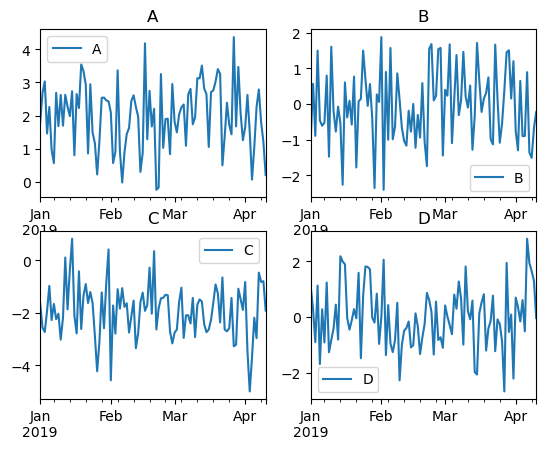

In [7]:
fig, axes = plt.subplots(2, 2)

df['A'].plot(ax=axes[0,0], legend=True, title=df.columns[0])
df['B'].plot(ax=axes[0,1], legend=True, title=df.columns[1])
df['C'].plot(ax=axes[1,0], legend=True, title=df.columns[2])
df['D'].plot(ax=axes[1,1], legend=True, title=df.columns[3])

Podría ser interesante graficar una columna respecto de otra, en lugar de usar el índice como etiquetas del eje x:

<Axes: xlabel='A', ylabel='B'>

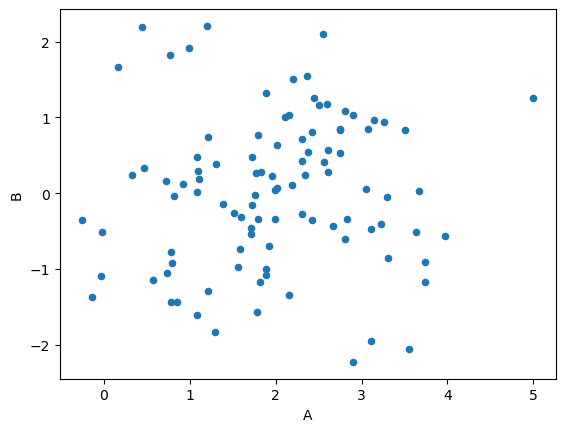

In [11]:
df.plot(x='A', y='B', kind='scatter')

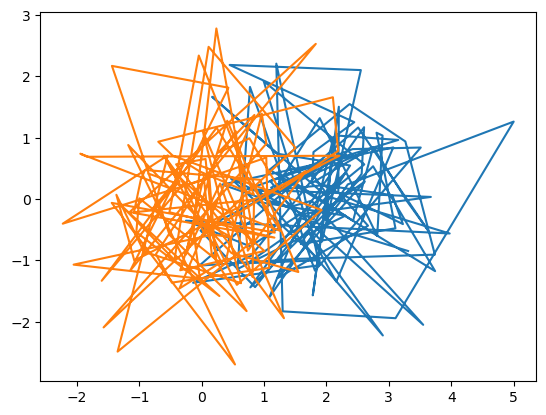

In [12]:
plt.plot(df['A'],df['B'])
plt.plot(df['B'],df['D'])

Y se pueden hacer fácilmente [otros tipos de gráficos](https://pandas.pydata.org/docs/user_guide/visualization.html#other-plots):

<Axes: >

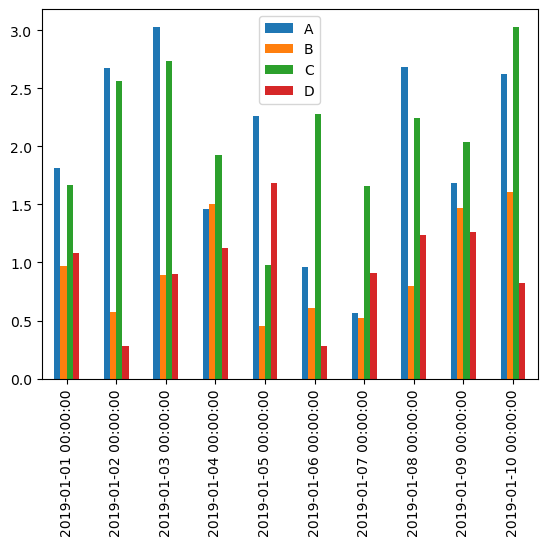

In [10]:
df.iloc[:10].abs().plot.bar()

## Un ejemplo con datos reales: Gapminder

Los ejemplos anteriores sirven para entender la mecánica de `plot`, pero con datos reales aparecen preguntas más interesantes. Vamos a leer desde la web un CSV de Gapminder con información de países: población, continente, esperanza de vida y PBI per cápita cada 5 años.

Fuente: <https://raw.githubusercontent.com/resbaz/r-novice-gapminder-files/master/data/gapminder-FiveYearData.csv>

In [13]:
gapminder_url = "https://raw.githubusercontent.com/resbaz/r-novice-gapminder-files/master/data/gapminder-FiveYearData.csv"

gapminder = pd.read_csv(gapminder_url)


In [14]:
gapminder.head(20)

,country,year,pop,continent,lifeExp,gdpPercap
0,Afghanistan,1952,8425333.0,Asia,28.801,779.445314
1,Afghanistan,1957,9240934.0,Asia,30.332,820.853030
2,Afghanistan,1962,10267083.0,Asia,31.997,853.100710
3,Afghanistan,1967,11537966.0,Asia,34.020,836.197138
4,Afghanistan,1972,13079460.0,Asia,36.088,739.981106
5,Afghanistan,1977,14880372.0,Asia,38.438,786.113360
6,Afghanistan,1982,12881816.0,Asia,39.854,978.011439
7,Afghanistan,1987,13867957.0,Asia,40.822,852.395945
8,Afghanistan,1992,16317921.0,Asia,41.674,649.341395
9,Afghanistan,1997,22227415.0,Asia,41.763,635.341351


In [15]:
gapminder.info()

<class 'pandas.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   str    
 1   year       1704 non-null   int64  
 2   pop        1704 non-null   float64
 3   continent  1704 non-null   str    
 4   lifeExp    1704 non-null   float64
 5   gdpPercap  1704 non-null   float64
dtypes: float64(3), int64(1), str(2)
memory usage: 103.7 KB


Una primera pregunta puede ser cómo cambia la esperanza de vida promedio por continente a lo largo del tiempo. Para eso hacemos una tabla pivote: años en las filas, continentes en las columnas.

Para eso usamos el método de pandas `pivot_table`, que permite reorganizar datos en formato largo y resumirlos en una tabla de doble entrada. Con `index` indicamos qué variable queremos en las filas, con `columns` cuál queremos desplegar como columnas, con `values` qué variable numérica queremos resumir y con `aggfunc` qué operación aplicar cuando hay más de un valor para cada combinación. En este caso, para cada par `(año, continente)` calculamos el promedio de `lifeExp`.

In [17]:
vida_por_continente = gapminder.pivot_table(
    index="year",
    columns="continent",
    values="lifeExp",
    aggfunc="mean",
)
vida_por_continente

continent,Africa,Americas,Asia,Europe,Oceania
year,,,,,
1952,39.135500,53.27984,46.314394,64.408500,69.2550
1957,41.266346,55.96028,49.318544,66.703067,70.2950
1962,43.319442,58.39876,51.563223,68.539233,71.0850
1967,45.334538,60.41092,54.663640,69.737600,71.3100
1972,47.450942,62.39492,57.319269,70.775033,71.9100
1977,49.580423,64.39156,59.610556,71.937767,72.8550
1982,51.592865,66.22884,62.617939,72.806400,74.2900
1987,53.344788,68.09072,64.851182,73.642167,75.3200
1992,53.629577,69.56836,66.537212,74.440100,76.9450


Text(0, 0.5, 'Esperanza de vida')

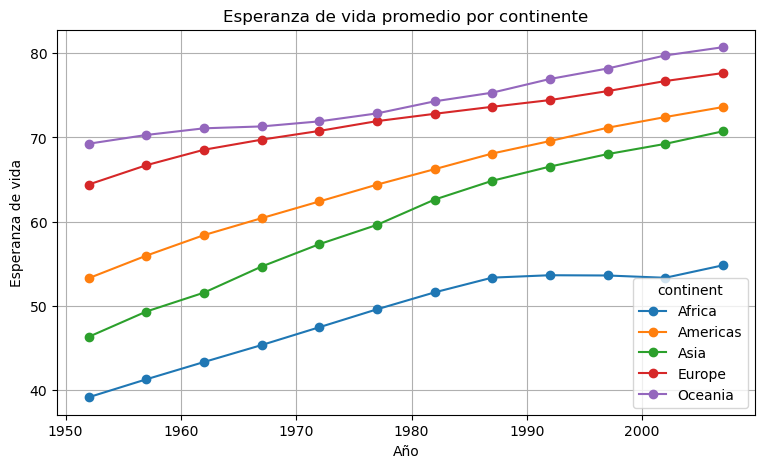

In [18]:

vida_por_continente.plot(
    figsize=(9, 5),
    marker="o",
    title="Esperanza de vida promedio por continente",
    grid=True,
)
plt.xlabel("Año")
plt.ylabel("Esperanza de vida")

También podemos mirar un año particular y comparar países. En este caso cada punto es un país: el eje x muestra PBI per cápita, el eje y esperanza de vida, el tamaño representa población y el color separa continentes.

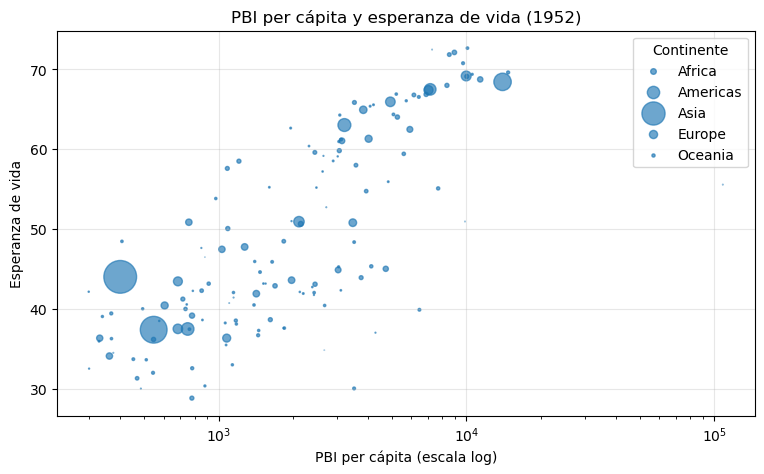

In [22]:
anio = 1952
datos_anio = gapminder[gapminder["year"] == anio]

fig, ax = plt.subplots(figsize=(9, 5))

for continente, datos_continente in datos_anio.groupby("continent"):
    datos_continente.plot.scatter(
        x="gdpPercap",
        y="lifeExp",
        s=datos_continente["pop"] / 1_000_000,
        alpha=0.65,
        label=continente,
        ax=ax,
    )

ax.set_xscale("log")
ax.set_title(f"PBI per cápita y esperanza de vida ({anio})")
ax.set_xlabel("PBI per cápita (escala log)")
ax.set_ylabel("Esperanza de vida")
ax.grid(True, alpha=0.3)
ax.legend(title="Continente")

Con los mismos datos podemos hacer gráficos más agregados. Por ejemplo, población total por continente para un año determinado:

continent
Asia        3811.953827
Africa       929.539692
Americas     898.871184
Europe       586.098529
Oceania       24.549947
Name: pop, dtype: float64


<Axes: title={'center': 'Población por continente (2007)'}, xlabel='continent', ylabel='Millones de personas'>

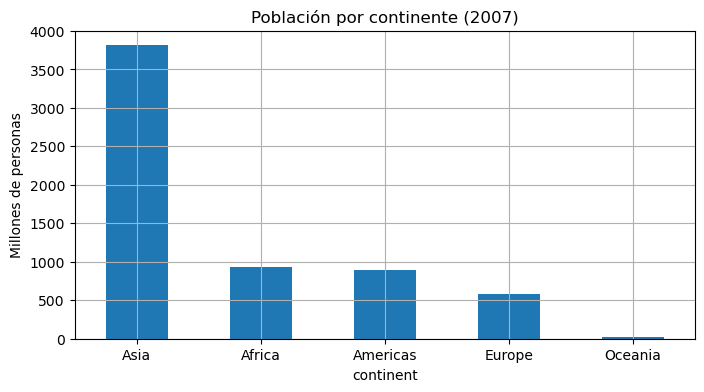

In [21]:
poblacion_por_continente = (
    datos_anio.groupby("continent")["pop"]
    .sum()
    .sort_values(ascending=False)
    / 1_000_000
)
print(poblacion_por_continente)

poblacion_por_continente.plot.bar(
    figsize=(8, 4),
    title=f"Población por continente ({anio})",
    ylabel="Millones de personas",
    rot=0,
    grid=True,
)

Y si queremos comparar distribuciones, podemos usar un `boxplot`. Acá se ve la distribución de esperanza de vida de los países dentro de cada continente.

Text(0, 0.5, 'Esperanza de vida')

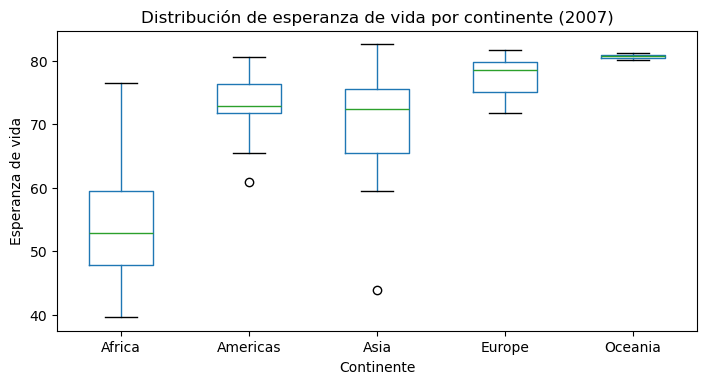

In [18]:
datos_anio.boxplot(
    column="lifeExp",
    by="continent",
    figsize=(8, 4),
    grid=False,
)
plt.title(f"Distribución de esperanza de vida por continente ({anio})")
plt.suptitle("")
plt.xlabel("Continente")
plt.ylabel("Esperanza de vida")

## Creando un dashboard

La misma fuente de datos también se puede explorar con una app simple de (Streamlit)[https://streamlit.io/]. En este repo hay un ejemplo en `etl-03/gapminder_streamlit.py`. Para instalar `streamlit`
```bash
conda activate <mi_entorno>
conda install -c conda-forge streamlit
```
> De existir problemas de incompatibilidad entre streamlit y conda, instalar

```bash
conda install -n diplo-ia -c conda-forge "streamlit>=1.58"
```